# Khảo sát và thẩm định Phương án 2:Inventory Risk Classification

In [1]:
import os
import sys
import time
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    classification_report, confusion_matrix, precision_recall_curve, auc
)
import lightgbm as lgb
import kagglehub

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print("Moi truong khoi tao thanh cong.")

Moi truong khoi tao thanh cong.


In [2]:
# Xac dinh duong dan 2 bo du lieu
# 1. Electronics Sales Dataset (dataset chinh)
electronics_local = os.path.abspath("../data/raw")
if os.path.exists(electronics_local) and os.path.exists(os.path.join(electronics_local, "SalesOrders.csv")):
    electronics_path = electronics_local
    print(f"Electronics Dataset: Su dung thu muc noi bo -> {electronics_path}")
else:
    electronics_path = kagglehub.dataset_download("fahdelatiby/electronics-sales-dataset-b-tech-style")
    print(f"Electronics Dataset: Tai qua kagglehub -> {electronics_path}")

# 2. Instacart Market Basket Analysis (dataset benchmark)
instacart_path = kagglehub.dataset_download("psparks/instacart-market-basket-analysis")
print(f"Instacart Dataset: Tai qua kagglehub -> {instacart_path}")

print("\n--- Danh sach file Electronics Sales Dataset (top 10 file tieu bieu) ---")
elec_files = sorted(os.listdir(electronics_path))
print(f"Tong so file: {len(elec_files)} file csv")
for f in elec_files[:10]:
    sz = os.path.getsize(os.path.join(electronics_path, f)) / (1024 * 1024)
    print(f"  {f:<30} | {sz:>8.2f} MB")

print("\n--- Danh sach file Instacart Dataset ---")
insta_files = sorted(os.listdir(instacart_path))
for f in insta_files:
    sz = os.path.getsize(os.path.join(instacart_path, f)) / (1024 * 1024)
    print(f"  {f:<30} | {sz:>8.2f} MB")

Electronics Dataset: Su dung thu muc noi bo -> D:\DS317_DoAn_KhaiPhaDuLieu\data\raw


Instacart Dataset: Tai qua kagglehub -> C:\Users\Admin\.cache\kagglehub\datasets\psparks\instacart-market-basket-analysis\versions\1

--- Danh sach file Electronics Sales Dataset (top 10 file tieu bieu) ---
Tong so file: 27 file csv
  BrandSubcategoryMap.csv        |     0.01 MB
  Brands.csv                     |     0.00 MB
  Categories.csv                 |     0.00 MB
  CustomerReturns.csv            |     2.35 MB
  Customers.csv                  |     8.01 MB
  Governorates.csv               |     0.00 MB
  InventoryBalances.csv          |     0.54 MB
  InventoryMovements.csv         |    98.93 MB
  Locations.csv                  |     0.00 MB
  PaymentMethods.csv             |     0.00 MB

--- Danh sach file Instacart Dataset ---
  aisles.csv                     |     0.00 MB
  departments.csv                |     0.00 MB
  order_products__prior.csv      |   550.80 MB
  order_products__train.csv      |    23.54 MB
  orders.csv                     |   103.92 MB
  products.csv      

## 1. Thẩm định khía cạnh Dữ liệu (Data Feasibility)

### 1.1. Thẩm định tính khả thi trên Dataset tham khảo (Instacart) đối với Phương án 2

In [3]:
# Kiem tra schema cac bang quan trong cua Instacart
insta_orders = pd.read_csv(os.path.join(instacart_path, "orders.csv"), nrows=5)
insta_products = pd.read_csv(os.path.join(instacart_path, "products.csv"), nrows=5)
insta_op = pd.read_csv(os.path.join(instacart_path, "order_products__train.csv"), nrows=5)

print("Schema bang orders.csv:")
print(insta_orders.columns.tolist())
print("\nSchema bang products.csv:")
print(insta_products.columns.tolist())
print("\nSchema bang order_products__train.csv:")
print(insta_op.columns.tolist())

# Kiem tra su ton tai cua cac truong bat buoc cho Phuong an 2
has_inventory_table = any("inventory" in f.lower() or "stock" in f.lower() for f in insta_files)
has_stock_col = any("stock" in c.lower() or "inventory" in c.lower() or "qty" in c.lower() 
                    for df in [insta_orders, insta_products, insta_op] for c in df.columns)
has_calendar_date = "order_date" in insta_orders.columns or "date" in insta_orders.columns

print("\n--- Ket qua kiem tra yeu cau du lieu PA2 tren Instacart ---")
print(f"Co bang ton kho / bien dong kho:   {has_inventory_table}")
print(f"Co cot so luong ton kho (Stock):   {has_stock_col}")
print(f"Co moc thoi gian lich (Calendar):  {has_calendar_date}")
print(f"Truong thoi gian kha dung:         {[c for c in insta_orders.columns if 'order' in c or 'day' in c]}")

Schema bang orders.csv:
['order_id', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']

Schema bang products.csv:
['product_id', 'product_name', 'aisle_id', 'department_id']

Schema bang order_products__train.csv:
['order_id', 'product_id', 'add_to_cart_order', 'reordered']

--- Ket qua kiem tra yeu cau du lieu PA2 tren Instacart ---
Co bang ton kho / bien dong kho:   False
Co cot so luong ton kho (Stock):   False
Co moc thoi gian lich (Calendar):  False
Truong thoi gian kha dung:         ['order_id', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']


**Đánh giá thực nghiệm trên Instacart đối với Phương án 2:**
1. **Thiếu biến tồn kho (Inventory = None):** Instacart hoàn toàn không có bảng kho, không có số lượng tồn kho (on-hand balance), không có dữ liệu nhập kho (purchase receipts) hay biến động kho. Do đó, **không thể tính chỉ số Coverage** ($EndInventory \div Sales$).
2. **Thiếu mốc thời gian tuyệt đối:** Trường thời gian trong Instacart chỉ là `days_since_prior_order` (khoảng cách ngày tương đối của người dùng), `order_dow` (thứ) và `order_hour_of_day` (giờ). Không có ngày tháng năm thực tế để lập chuỗi thời gian tuần $t$.
3. **Kết luận về Instacart đối với PA2:** **KHÔNG ĐẠT (Infeasible)**. Instacart chỉ phù hợp làm benchmark cho Phương án khai phá luật kết hợp giỏ hàng (Market Basket Analysis), hoàn toàn không thể dùng cho Phương án 2.

### 1.2. Thẩm định cấu trúc và liên kết bảng trên Electronics Sales Dataset (Dataset chính)
Phương án 2 yêu cầu liên kết giữa:
- Lịch sử bán hàng: `SalesOrders`, `SalesOrderLines`
- Biến động và số dư tồn kho: `InventoryMovements`, `InventoryBalances`
- Thông tin phân cấp sản phẩm: `Products`, `ProductVariants`

In [4]:
# Doc cac bang can thiet
t0 = time.time()
so = pd.read_csv(os.path.join(electronics_path, "SalesOrders.csv"), 
                 usecols=['SalesOrderID', 'OrderDate', 'OrderStatus'])
sol = pd.read_csv(os.path.join(electronics_path, "SalesOrderLines.csv"), 
                  usecols=['SalesOrderID', 'SKU_ID', 'Quantity', 'ActualSellingPrice', 'PromotionID'])
im = pd.read_csv(os.path.join(electronics_path, "InventoryMovements.csv"),
                 usecols=['MovementDateTime', 'SKU_ID', 'MovementType', 'Quantity', 'ToCondition'])
ib = pd.read_csv(os.path.join(electronics_path, "InventoryBalances.csv"))

print(f"Thoi gian nạp du lieu: {time.time()-t0:.2f}s")
print(f"SalesOrders:        {len(so):>10,d} dong | {so.shape[1]} cot")
print(f"SalesOrderLines:    {len(sol):>10,d} dong | {sol.shape[1]} cot")
print(f"InventoryMovements: {len(im):>10,d} dong | {im.shape[1]} cot")
print(f"InventoryBalances:  {len(ib):>10,d} dong | {ib.shape[1]} cot")

# Kiem tra khoa SKU_ID
skus_sales = set(sol['SKU_ID'].unique())
skus_inv_mov = set(im['SKU_ID'].unique())
skus_inv_bal = set(ib['SKU_ID'].unique())

print(f"\nSo luong SKU trong SalesOrderLines:    {len(skus_sales):,d}")
print(f"So luong SKU trong InventoryMovements: {len(skus_inv_mov):,d}")
print(f"So luong SKU trong InventoryBalances:  {len(skus_inv_bal):,d}")

overlap_sales_inv = skus_sales.intersection(skus_inv_mov)
print(f"So SKU giao thoa giua Sales va Movements: {len(overlap_sales_inv):,d} ({100*len(overlap_sales_inv)/len(skus_sales):.2f}%)")

Thoi gian nạp du lieu: 1.70s
SalesOrders:           322,577 dong | 3 cot
SalesOrderLines:       579,572 dong | 5 cot
InventoryMovements:    961,048 dong | 5 cot
InventoryBalances:      12,104 dong | 9 cot

So luong SKU trong SalesOrderLines:    871
So luong SKU trong InventoryMovements: 877
So luong SKU trong InventoryBalances:  902
So SKU giao thoa giua Sales va Movements: 871 (100.00%)


In [5]:
# Kiem tra truc thoi gian giua SalesOrders va InventoryMovements
so['OrderDate'] = pd.to_datetime(so['OrderDate'])
im['MovementDateTime'] = pd.to_datetime(im['MovementDateTime'])

print("--- Khoang thoi gian goc ---")
print(f"SalesOrders min/max:        {so['OrderDate'].min().strftime('%Y-%m-%d')} den {so['OrderDate'].max().strftime('%Y-%m-%d')}")
print(f"InventoryMovements min/max: {im['MovementDateTime'].min().strftime('%Y-%m-%d')} den {im['MovementDateTime'].max().strftime('%Y-%m-%d')}")

# Phan bo don hang theo nam
so['Year'] = so['OrderDate'].dt.year
orders_by_year = so.groupby('Year')['SalesOrderID'].count()
print("\nPhan bo don hang theo nam trong SalesOrders:")
for y, cnt in orders_by_year.items():
    print(f"  Nam {y}: {cnt:>10,d} don ({100*cnt/len(so):>6.2f}%)")

# Giai doan hoat dong dong bo thuc te: 2023-07-01 den 2025-12-31
valid_period_mask = (so['OrderDate'] >= '2023-07-01') & (so['OrderDate'] <= '2025-12-31')
print(f"\nDon hang trong giai doan 07/2023 - 12/2025: {valid_period_mask.sum():,d} / {len(so):,d} ({100*valid_period_mask.mean():.3f}%)")
print("Cac don truoc 07/2023 (13 don) va sau 2025 (16 don) la outlier/test, khong co phat sinh ton kho tuong ung.")

--- Khoang thoi gian goc ---
SalesOrders min/max:        2022-08-15 den 2026-12-03
InventoryMovements min/max: 2023-07-01 den 2025-12-31

Phan bo don hang theo nam trong SalesOrders:
  Nam 2022:          5 don (  0.00%)
  Nam 2023:     55,451 don ( 17.19%)
  Nam 2024:    127,493 don ( 39.52%)
  Nam 2025:    139,612 don ( 43.28%)
  Nam 2026:         16 don (  0.00%)

Don hang trong giai doan 07/2023 - 12/2025: 322,548 / 322,577 (99.991%)
Cac don truoc 07/2023 (13 don) va sau 2025 (16 don) la outlier/test, khong co phat sinh ton kho tuong ung.


In [6]:
# 1.3. Tai lap chuoi ton kho luy ke (Cumulative Inventory)
# Loc du lieu trong giai doan chuan 2023-07-01 den 2025-12-31
im_clean = im[(im['MovementDateTime'] >= '2023-07-01') & (im['MovementDateTime'] <= '2025-12-31')].copy()

# Xac dinh chieu bien dong so luong (Net Quantity Change)
conditions = [
    im_clean['MovementType'].isin(['Opening Balance', 'Purchase Receipt', 'Customer Return']),
    im_clean['MovementType'].isin(['Sale', 'Purchase Return', 'Replacement Issue']),
    im_clean['MovementType'] == 'Adjustment',
    im_clean['MovementType'] == 'Internal Transfer'
]
choices = [
    im_clean['Quantity'],
    -im_clean['Quantity'],
    np.where(im_clean['ToCondition'] == 'Available', im_clean['Quantity'], -im_clean['Quantity']),
    0
]
im_clean['NetQtyChange'] = np.select(conditions, choices, default=0)
im_clean['Week'] = im_clean['MovementDateTime'].dt.to_period('W').dt.start_time

# Tong hop bien dong kho theo SKU va Tuan
weekly_inv = im_clean.groupby(['SKU_ID', 'Week'])['NetQtyChange'].sum().reset_index()
weekly_inv = weekly_inv.sort_values(['SKU_ID', 'Week'])
weekly_inv['EndInventory'] = weekly_inv.groupby('SKU_ID')['NetQtyChange'].cumsum()

print("--- Thong ke ton kho luy ke cuoi tuan (EndInventory) tren 877 SKU ---")
print(weekly_inv['EndInventory'].describe())
print(f"Tong so quan sat SKU x Tuan co bien dong: {len(weekly_inv):,d}")
print(f"So luong gia tri ton kho am (< 0):         {(weekly_inv['EndInventory'] < 0).sum():,d}")
print(f"Ty le ton kho hop le (>= 0):               {100*(weekly_inv['EndInventory'] >= 0).mean():.2f}%")

--- Thong ke ton kho luy ke cuoi tuan (EndInventory) tren 877 SKU ---
count   72232.0000
mean       55.1079
std        19.4796
min         0.0000
25%        41.0000
50%        54.0000
75%        68.0000
max       191.0000
Name: EndInventory, dtype: float64
Tong so quan sat SKU x Tuan co bien dong: 72,232
So luong gia tri ton kho am (< 0):         0
Ty le ton kho hop le (>= 0):               100.00%


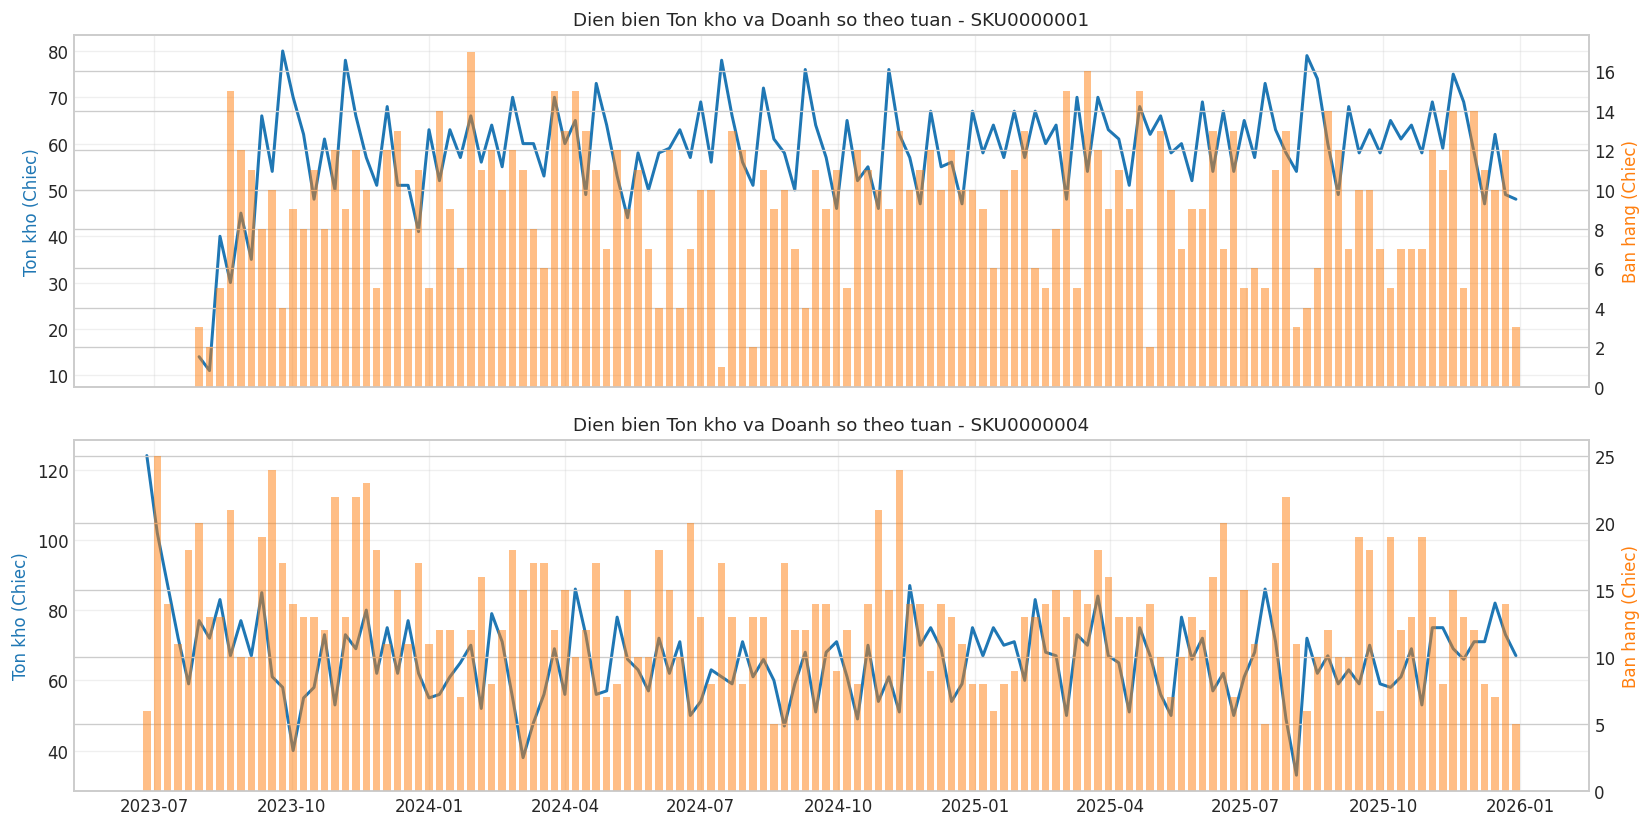

In [7]:
# Truc quan hoa chuoi thoi gian ton kho va doanh so cua 2 SKU tieu bieu
so_clean = so[(so['OrderDate'] >= '2023-07-01') & (so['OrderDate'] <= '2025-12-31') & (so['OrderStatus'] != 'Cancelled')].copy()
sales_m = pd.merge(sol, so_clean[['SalesOrderID', 'OrderDate']], on='SalesOrderID')
sales_m['Week'] = sales_m['OrderDate'].dt.to_period('W').dt.start_time

sample_skus = ['SKU0000001', 'SKU0000004']
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

for i, sku in enumerate(sample_skus):
    sku_inv = weekly_inv[weekly_inv['SKU_ID'] == sku].set_index('Week')['EndInventory']
    sku_sales = sales_m[sales_m['SKU_ID'] == sku].groupby('Week')['Quantity'].sum()
    
    ax1 = axes[i]
    ax2 = ax1.twinx()
    
    ax1.plot(sku_inv.index, sku_inv.values, color='#1f77b4', lw=1.8, label='Ton kho cuoi tuan (EndInventory)')
    ax2.bar(sku_sales.index, sku_sales.values, width=5, color='#ff7f0e', alpha=0.5, label='So luong ban (SalesQty)')
    
    ax1.set_ylabel('Ton kho (Chiec)', color='#1f77b4')
    ax2.set_ylabel('Ban hang (Chiec)', color='#ff7f0e')
    ax1.set_title(f"Dien bien Ton kho va Doanh so theo tuan - {sku}")
    ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Thẩm định khía cạnh Kỹ thuật (Technical Feasibility)

### 2.1. Thiết kế đơn vị phân tích và khung bảng dữ liệu (Panel Construction)
- **Đơn vị phân tích:** Một quan sát = Một sản phẩm ($SKU$) trong một tuần $t$.
- **Lưới thời gian chuẩn:** Tạo Cartesian product giữa 871 SKU và 130 tuần liên tục (07/2023 $\to$ 12/2025).
- **Quy tắc gán nhãn nghiệp vụ (Rule-based Labeling):**
  $$\text{Coverage}(t) = \frac{\text{EndInventory}(t)}{\frac{1}{4} \sum_{k=1}^4 \text{Sales}(t+k) + \varepsilon}$$
  - **High:** $\text{Coverage}(t) \ge P_{85}$ (ngưỡng phân vị 85 trên tập Train) VÀ xu hướng bán 4 tuần gần nhất không tăng ($\text{SalesTrend}_{4w} \le 0$).
  - **Medium:** $P_{60} \le \text{Coverage}(t) < P_{85}$ hoặc ($\text{Coverage}(t) \ge P_{85}$ nhưng đang có xu hướng tăng trưởng).
  - **Low:** Các trường hợp còn lại.

In [8]:
# 1. Tong hop ban hang theo tuan
sales_m['Revenue'] = sales_m['ActualSellingPrice'] * sales_m['Quantity']
weekly_sales = sales_m.groupby(['SKU_ID', 'Week']).agg(
    WeeklyQty=('Quantity', 'sum'),
    WeeklyRevenue=('Revenue', 'sum'),
    AvgPrice=('ActualSellingPrice', 'mean'),
    PromoCount=('PromotionID', lambda x: x.notna().sum())
).reset_index()

# 2. Tao luoi Panel day du (SKU x Week)
all_skus = sorted(weekly_sales['SKU_ID'].unique())
all_weeks = pd.date_range('2023-07-03', '2025-12-22', freq='W-MON')
panel = pd.MultiIndex.from_product([all_skus, all_weeks], names=['SKU_ID', 'Week']).to_frame().reset_index(drop=True)

df = pd.merge(panel, weekly_sales, on=['SKU_ID', 'Week'], how='left')
df['WeeklyQty'] = df['WeeklyQty'].fillna(0)
df['WeeklyRevenue'] = df['WeeklyRevenue'].fillna(0)
df['PromoCount'] = df['PromoCount'].fillna(0)
df['AvgPrice'] = df.groupby('SKU_ID')['AvgPrice'].ffill().bfill()

df = pd.merge(df, weekly_inv[['SKU_ID', 'Week', 'NetQtyChange', 'EndInventory']], on=['SKU_ID', 'Week'], how='left')
df['NetQtyChange'] = df['NetQtyChange'].fillna(0)
df['EndInventory'] = df.groupby('SKU_ID')['EndInventory'].ffill().fillna(0)

# 3. Tao bien muc tieu (Future 4-week sales & Coverage)
df = df.sort_values(['SKU_ID', 'Week']).reset_index(drop=True)
for k in [1, 2, 3, 4]:
    df[f'FutureSales_{k}'] = df.groupby('SKU_ID')['WeeklyQty'].shift(-k)

df['FutureAvgSales_4w'] = df[['FutureSales_1', 'FutureSales_2', 'FutureSales_3', 'FutureSales_4']].mean(axis=1)
eps = 0.5
df['Coverage'] = df['EndInventory'] / (df['FutureAvgSales_4w'] + eps)

# Tinh xu huong ban 4 tuan qua
df['Sales_Lag_4'] = df.groupby('SKU_ID')['WeeklyQty'].shift(4)
df['SalesTrend_4w'] = df['WeeklyQty'] - df['Sales_Lag_4']

print(f"Kich thuoc Panel tong the: {df.shape[0]:,d} dong | {df.shape[1]} cot")

Kich thuoc Panel tong the: 113,230 dong | 16 cot


In [9]:
# 2.2. Ky thuat dac trung (Feature Engineering - strictly <= t, no leakage)
# Dac trung do tre (Lags)
for lag in [1, 2, 8]:
    df[f'Sales_Lag_{lag}'] = df.groupby('SKU_ID')['WeeklyQty'].shift(lag)

# Rolling statistics (dich 1 tuan de khong trung lap tuan hien tai)
df['Sales_RollingMean_4w'] = df.groupby('SKU_ID')['WeeklyQty'].shift(1).rolling(4, min_periods=4).mean()
df['Sales_RollingStd_4w'] = df.groupby('SKU_ID')['WeeklyQty'].shift(1).rolling(4, min_periods=4).std().fillna(0)
df['Sales_RollingMean_8w'] = df.groupby('SKU_ID')['WeeklyQty'].shift(1).rolling(8, min_periods=8).mean()

# Past Coverage (uoc luong tuong doi trong qua khu tai thoi diem t)
df['PastCoverage'] = df['EndInventory'] / (df['Sales_RollingMean_4w'] + eps)

# Dac trung lich
df['Month'] = df['Week'].dt.month
df['WeekOfYear'] = df['Week'].dt.isocalendar().week.astype(int)

# Loc cac dong hop le (co du lich su lag 8 va tuong lai 4 tuan)
valid_df = df.dropna(subset=['Coverage', 'Sales_Lag_8', 'Sales_RollingMean_8w', 'PastCoverage']).copy()
valid_df = valid_df.sort_values(['Week', 'SKU_ID']).reset_index(drop=True)

print(f"So luong quan sat hop le de huan luyen & danh gia: {len(valid_df):,d} dong")
print(f"So tuan hop le: {valid_df['Week'].nunique()} tuan ({valid_df['Week'].min().strftime('%Y-%m-%d')} -> {valid_df['Week'].max().strftime('%Y-%m-%d')})")

So luong quan sat hop le de huan luyen & danh gia: 105,391 dong
So tuan hop le: 121 tuan (2023-08-28 -> 2025-12-15)


In [10]:
# 2.3. Chien luoc chia du lieu theo thoi gian co khoang dem 4 tuan (Gap Split)
unique_weeks = sorted(valid_df['Week'].unique())
n_weeks = len(unique_weeks)

train_weeks_cnt = int(n_weeks * 0.70)
val_weeks_cnt = int(n_weeks * 0.15)
gap_weeks = 4

train_end_idx = train_weeks_cnt
val_start_idx = train_end_idx + gap_weeks
val_end_idx = val_start_idx + val_weeks_cnt
test_start_idx = val_end_idx + gap_weeks

train_weeks = unique_weeks[:train_end_idx]
val_weeks = unique_weeks[val_start_idx:val_end_idx]
test_weeks = unique_weeks[test_start_idx:]

train_set = valid_df[valid_df['Week'].isin(train_weeks)].copy()
val_set = valid_df[valid_df['Week'].isin(val_weeks)].copy()
test_set = valid_df[valid_df['Week'].isin(test_weeks)].copy()

# Uoc luong nguong phan vi P60 va P85 CHI TREN TAP TRAIN de chong ro ri du lieu
p60 = train_set['Coverage'].quantile(0.60)
p85 = train_set['Coverage'].quantile(0.85)

print(f"Tong so tuan: {n_weeks}")
print(f"Train set: {len(train_weeks):>2} tuan ({train_weeks[0].strftime('%Y-%m-%d')} -> {train_weeks[-1].strftime('%Y-%m-%d')}) | {len(train_set):>6,d} dong")
print(f"Gap 1:     {gap_weeks:>2} tuan (Khoang dem ngan cach Train va Val tranh ro ri nhan 4 tuan)")
print(f"Val set:   {len(val_weeks):>2} tuan ({val_weeks[0].strftime('%Y-%m-%d')} -> {val_weeks[-1].strftime('%Y-%m-%d')}) | {len(val_set):>6,d} dong")
print(f"Gap 2:     {gap_weeks:>2} tuan (Khoang dem ngan cach Val va Test)")
print(f"Test set:  {len(test_weeks):>2} tuan ({test_weeks[0].strftime('%Y-%m-%d')} -> {test_weeks[-1].strftime('%Y-%m-%d')}) | {len(test_set):>6,d} dong")
print(f"\nNguong Coverage uoc tinh tren Train: P60 = {p60:.2f}, P85 = {p85:.2f}")

# Gan nhan InventoryRisk
for subset in [train_set, val_set, test_set]:
    subset['Target'] = np.where(
        (subset['Coverage'] >= p85) & (subset['SalesTrend_4w'] <= 0), 2, # High
        np.where(subset['Coverage'] >= p60, 1, 0) # Medium / Low
    )

print("\nPhan bo nhan tren Tap Train:")
print(train_set['Target'].value_counts(normalize=True).rename({0:'Low', 1:'Medium', 2:'High'}))
print("\nPhan bo nhan tren Tap Test:")
print(test_set['Target'].value_counts(normalize=True).rename({0:'Low', 1:'Medium', 2:'High'}))

Tong so tuan: 121
Train set: 84 tuan (2023-08-28 -> 2025-03-31) | 73,164 dong
Gap 1:      4 tuan (Khoang dem ngan cach Train va Val tranh ro ri nhan 4 tuan)
Val set:   18 tuan (2025-05-05 -> 2025-09-01) | 15,678 dong
Gap 2:      4 tuan (Khoang dem ngan cach Val va Test)
Test set:  11 tuan (2025-10-06 -> 2025-12-15) |  9,581 dong

Nguong Coverage uoc tinh tren Train: P60 = 7.49, P85 = 18.15



Phan bo nhan tren Tap Train:
Target
Low      0.5999
Medium   0.2781
High     0.1220
Name: proportion, dtype: float64

Phan bo nhan tren Tap Test:
Target
Low      0.3808
Medium   0.3477
High     0.2716
Name: proportion, dtype: float64


### 2.4. Khảo sát thực nghiệm & Trực quan hóa dữ liệu trước mô hình hóa (Exploratory Data Analysis)

Khảo sát phân bố nhãn, ma trận tương quan đặc trưng và xu hướng chuỗi thời gian nhằm thẩm định tính khả thi của bài toán và giải thích cơ chế phân loại:
1. **Biểu đồ so sánh phân bố nhãn mục tiêu (Target Distribution: Train vs Test):** Kiểm tra trực quan hiện tượng lệch pha phân bố (distribution shift) do việc tách tập dữ liệu theo thời gian có khoảng đệm 4 tuần (Gap Split).
2. **Biểu đồ ma trận tương quan (Correlation Matrix / Heatmap):** Nhìn rõ mối quan hệ tuyến tính giữa các đặc trưng quan trọng (`EndInventory`, `PastCoverage`, `WeeklyQty`, `SalesTrend_4w`,...) với biến mục tiêu `Target`.
3. **Biểu đồ xu hướng trung bình của các chỉ số chính theo thời gian nhóm theo nhãn rủi ro:** Phân tích sự phân kỳ hành vi giữa lượng hàng tồn kho và doanh số bán, giải thích sinh động lý do tại sao mô hình phân lớp được các nhóm này.

=== BANG PHAN BO NHAN MUC TIEU (TRAIN VS TEST) ===
                 Train Count  Train (%)  Test Count  Test (%)
Target                                                       
Low Risk (0)           43894    59.9940        3648   38.0754
Medium Risk (1)        20346    27.8088        3331   34.7667
High Risk (2)           8924    12.1973        2602   27.1579


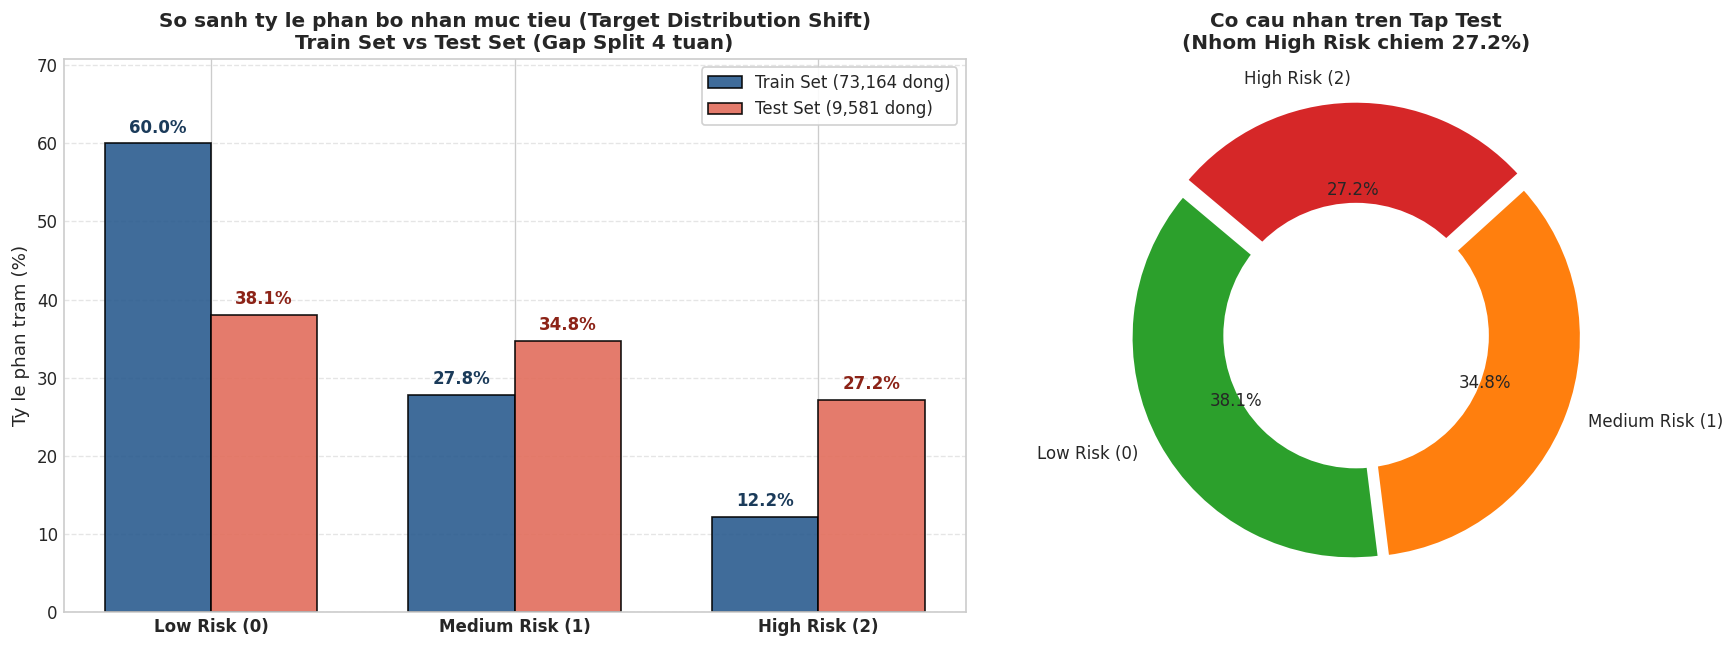


--- NHAN XET VE SU LECH PHA PHAN BO (DISTRIBUTION SHIFT) ---
1. Nhom High Risk tang manh tu 12.2% (Train) len 27.2% (Test).
2. Nhom Low Risk giam tu 60.0% (Train) xuong 38.1% (Test).
3. Y nghia: Phan anh dung thuc te chuoi thoi gian ban le dien tu (cuoi nam 2025 toc do tieu thu cham o mot so danh muc khien hang ton bi u dong).
4. Chien luoc xu ly: Mo hinh can duoc huan luyen voi class_weight='balanced' va danh gia bang PR-AUC de tranh bi danh lua boi do chinh xac tong the (Accuracy).


In [11]:
# 1. Bieu do so sanh phan bo nhan muc tieu (Target Distribution) giua Train va Test
# Giup kiem tra truc quan su lech pha phan bo (distribution shift) do Gap Split

target_labels = ['Low Risk (0)', 'Medium Risk (1)', 'High Risk (2)']
target_names = {0: 'Low Risk (0)', 1: 'Medium Risk (1)', 2: 'High Risk (2)'}

train_dist = train_set['Target'].map(target_names).value_counts()
test_dist = test_set['Target'].map(target_names).value_counts()

train_pct = (train_set['Target'].map(target_names).value_counts(normalize=True) * 100).reindex(target_labels)
test_pct = (test_set['Target'].map(target_names).value_counts(normalize=True) * 100).reindex(target_labels)

dist_summary = pd.DataFrame({
    'Train Count': train_dist.reindex(target_labels),
    'Train (%)': train_pct,
    'Test Count': test_dist.reindex(target_labels),
    'Test (%)': test_pct
})
print("=== BANG PHAN BO NHAN MUC TIEU (TRAIN VS TEST) ===")
print(dist_summary.to_string())

# Truc quan hoa bang bieu do
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})

# Subplot 1: Grouped Bar Chart so sanh ty le % giua Train va Test
x = np.arange(len(target_labels))
width = 0.35

rects1 = axes[0].bar(x - width/2, train_pct.values, width, label=f'Train Set ({len(train_set):,d} dong)',
                     color='#2b5c8f', edgecolor='black', alpha=0.9)
rects2 = axes[0].bar(x + width/2, test_pct.values, width, label=f'Test Set ({len(test_set):,d} dong)',
                     color='#e26d5c', edgecolor='black', alpha=0.9)

axes[0].set_title('So sanh ty le phan bo nhan muc tieu (Target Distribution Shift)\nTrain Set vs Test Set (Gap Split 4 tuan)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Ty le phan tram (%)', fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(target_labels, fontsize=10, fontweight='bold')
axes[0].set_ylim(0, max(max(train_pct), max(test_pct)) * 1.18)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Ghi gia tri % tren dau cot
for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points", ha='center', va='bottom',
                     fontsize=10, fontweight='bold', color='#1b3b5a')
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points", ha='center', va='bottom',
                     fontsize=10, fontweight='bold', color='#8c2317')

# Subplot 2: Donut Chart the hien co cau tap Test
colors = ['#2ca02c', '#ff7f0e', '#d62728']
high_pct_test = test_pct['High Risk (2)']
axes[1].pie(test_pct.values, labels=target_labels, autopct='%1.1f%%', startangle=140,
            colors=colors, explode=(0.02, 0.02, 0.06),
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
centre_circle = plt.Circle((0,0), 0.60, fc='white')
axes[1].add_artist(centre_circle)
axes[1].set_title(f'Co cau nhan tren Tap Test\n(Nhom High Risk chiem {high_pct_test:.1f}%)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n--- NHAN XET VE SU LECH PHA PHAN BO (DISTRIBUTION SHIFT) ---")
print(f"1. Nhom High Risk tang manh tu {train_pct['High Risk (2)']:.1f}% (Train) len {test_pct['High Risk (2)']:.1f}% (Test).")
print(f"2. Nhom Low Risk giam tu {train_pct['Low Risk (0)']:.1f}% (Train) xuong {test_pct['Low Risk (0)']:.1f}% (Test).")
print("3. Y nghia: Phan anh dung thuc te chuoi thoi gian ban le dien tu (cuoi nam 2025 toc do tieu thu cham o mot so danh muc khien hang ton bi u dong).")
print("4. Chien luoc xu ly: Mo hinh can duoc huan luyen voi class_weight='balanced' va danh gia bang PR-AUC de tranh bi danh lua boi do chinh xac tong the (Accuracy).")

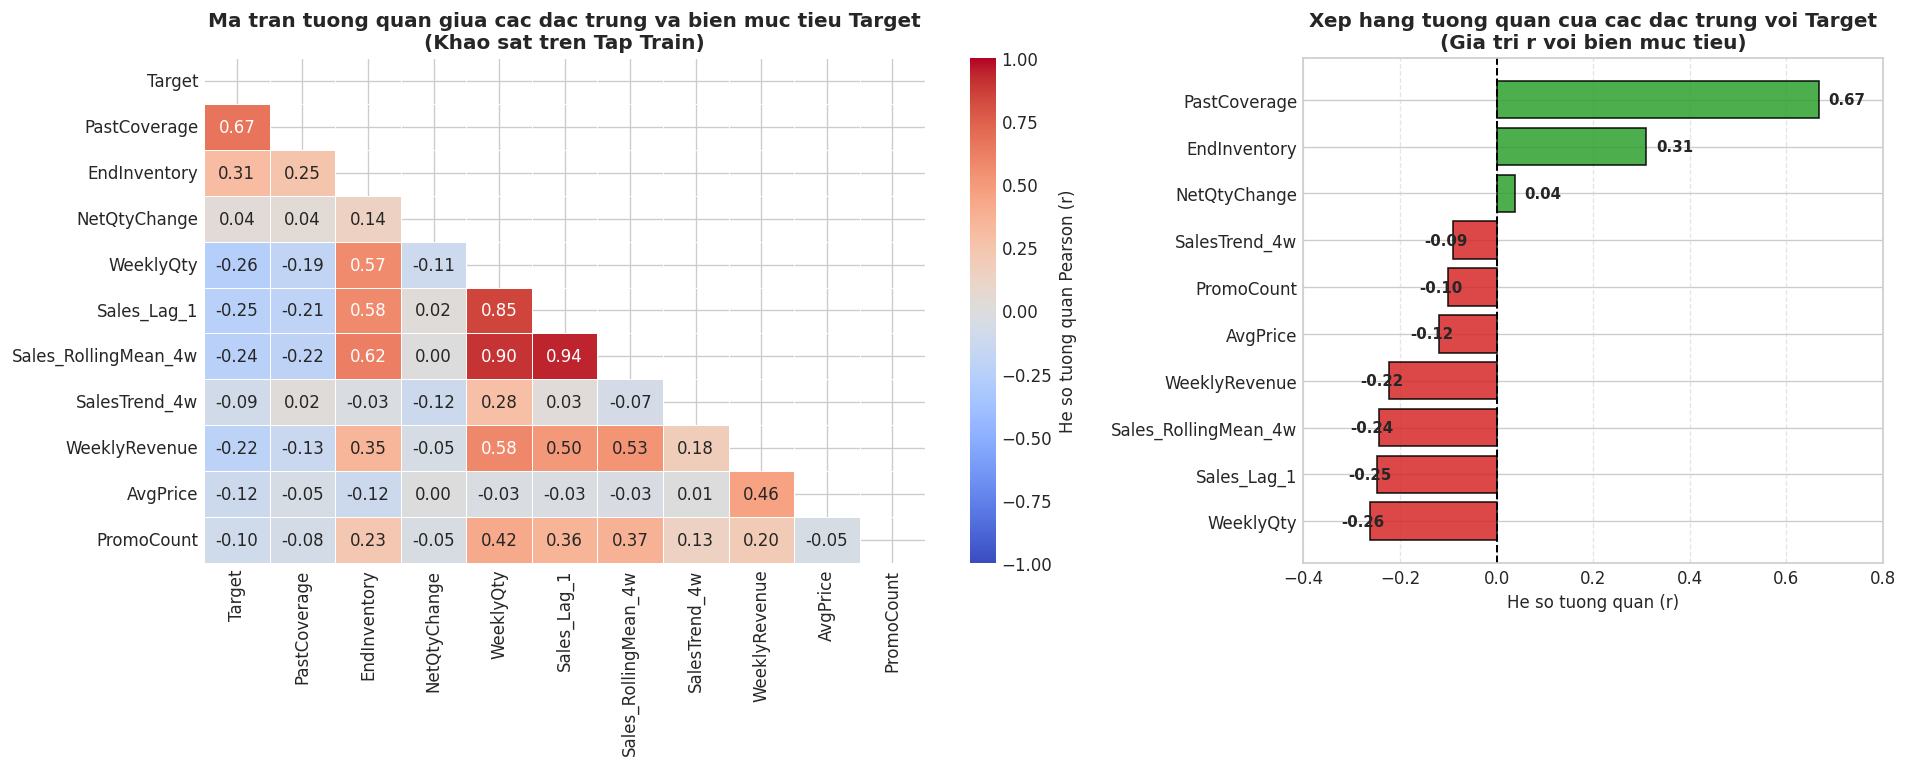


--- NHAN XET VE MOI QUAN HE TUONG QUAN VOI BIEN MUC TIEU TARGET ---
1. PastCoverage co tuong quan duong manh nhat voi Target (r = 0.67): Tuan nao co he so bao phu ton kho uoc tinh qua khu cao thi xac suat High Risk rat lon.
2. EndInventory co tuong quan duong dang ke (r = 0.31): Luong ton kho tuyet doi cao luon la dieu kien can gay ra nguy co ton u.
3. WeeklyQty (r = -0.26), Sales_Lag_1 (r = -0.25) va Sales_RollingMean_4w (r = -0.24) mang tuong quan am ro ret: San pham ban cang chay thi cang it rui ro bi xep vao nhom High Risk.
4. SalesTrend_4w mang tuong quan am (r = -0.09): Doanh so giam sut 4 tuan qua truc tiep canh bao rui ro tieu thu.


In [12]:
# 2. Bieu do tuong quan (Correlation Matrix / Heatmap)
# Quan sat moi quan he tuyen tinh giua cac dac trung quan trong va bien muc tieu Target tren tap Train

corr_features = [
    'Target', 'PastCoverage', 'EndInventory', 'NetQtyChange',
    'WeeklyQty', 'Sales_Lag_1', 'Sales_RollingMean_4w', 'SalesTrend_4w',
    'WeeklyRevenue', 'AvgPrice', 'PromoCount'
]

# Tinh ma tran tuong quan Pearson tren Tap Train (tranh data leakage tu Test)
train_corr = train_set[corr_features].corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1.4, 0.9]})

# Subplot 1: Heatmap day du
mask = np.triu(np.ones_like(train_corr, dtype=bool))
sns.heatmap(train_corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, cbar_kws={'label': 'He so tuong quan Pearson (r)'},
            linewidths=0.6, ax=axes[0])
axes[0].set_title('Ma tran tuong quan giua cac dac trung va bien muc tieu Target\n(Khao sat tren Tap Train)', fontsize=12, fontweight='bold')

# Subplot 2: Bar plot xep hang he so tuong quan voi bien Target
target_corr = train_corr['Target'].drop('Target').sort_values(ascending=True)
bar_colors = ['#d62728' if x < 0 else '#2ca02c' for x in target_corr.values]
bars = axes[1].barh(target_corr.index, target_corr.values, color=bar_colors, edgecolor='black', alpha=0.85)
axes[1].axvline(0, color='black', lw=1.2, linestyle='--')
axes[1].set_title('Xep hang tuong quan cua cac dac trung voi Target\n(Gia tri r voi bien muc tieu)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('He so tuong quan (r)', fontsize=10)
axes[1].set_xlim(-0.4, 0.8)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

# Ghi so tren thanh
for bar in bars:
    w = bar.get_width()
    offset = 0.02 if w >= 0 else -0.06
    axes[1].annotate(f'{w:.2f}', xy=(w + offset, bar.get_y() + bar.get_height()/2),
                     va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n--- NHAN XET VE MOI QUAN HE TUONG QUAN VOI BIEN MUC TIEU TARGET ---")
print(f"1. PastCoverage co tuong quan duong manh nhat voi Target (r = {train_corr.loc['PastCoverage', 'Target']:.2f}): Tuan nao co he so bao phu ton kho uoc tinh qua khu cao thi xac suat High Risk rat lon.")
print(f"2. EndInventory co tuong quan duong dang ke (r = {train_corr.loc['EndInventory', 'Target']:.2f}): Luong ton kho tuyet doi cao luon la dieu kien can gay ra nguy co ton u.")
print(f"3. WeeklyQty (r = {train_corr.loc['WeeklyQty', 'Target']:.2f}), Sales_Lag_1 (r = {train_corr.loc['Sales_Lag_1', 'Target']:.2f}) va Sales_RollingMean_4w (r = {train_corr.loc['Sales_RollingMean_4w', 'Target']:.2f}) mang tuong quan am ro ret: San pham ban cang chay thi cang it rui ro bi xep vao nhom High Risk.")
print(f"4. SalesTrend_4w mang tuong quan am (r = {train_corr.loc['SalesTrend_4w', 'Target']:.2f}): Doanh so giam sut 4 tuan qua truc tiep canh bao rui ro tieu thu.")

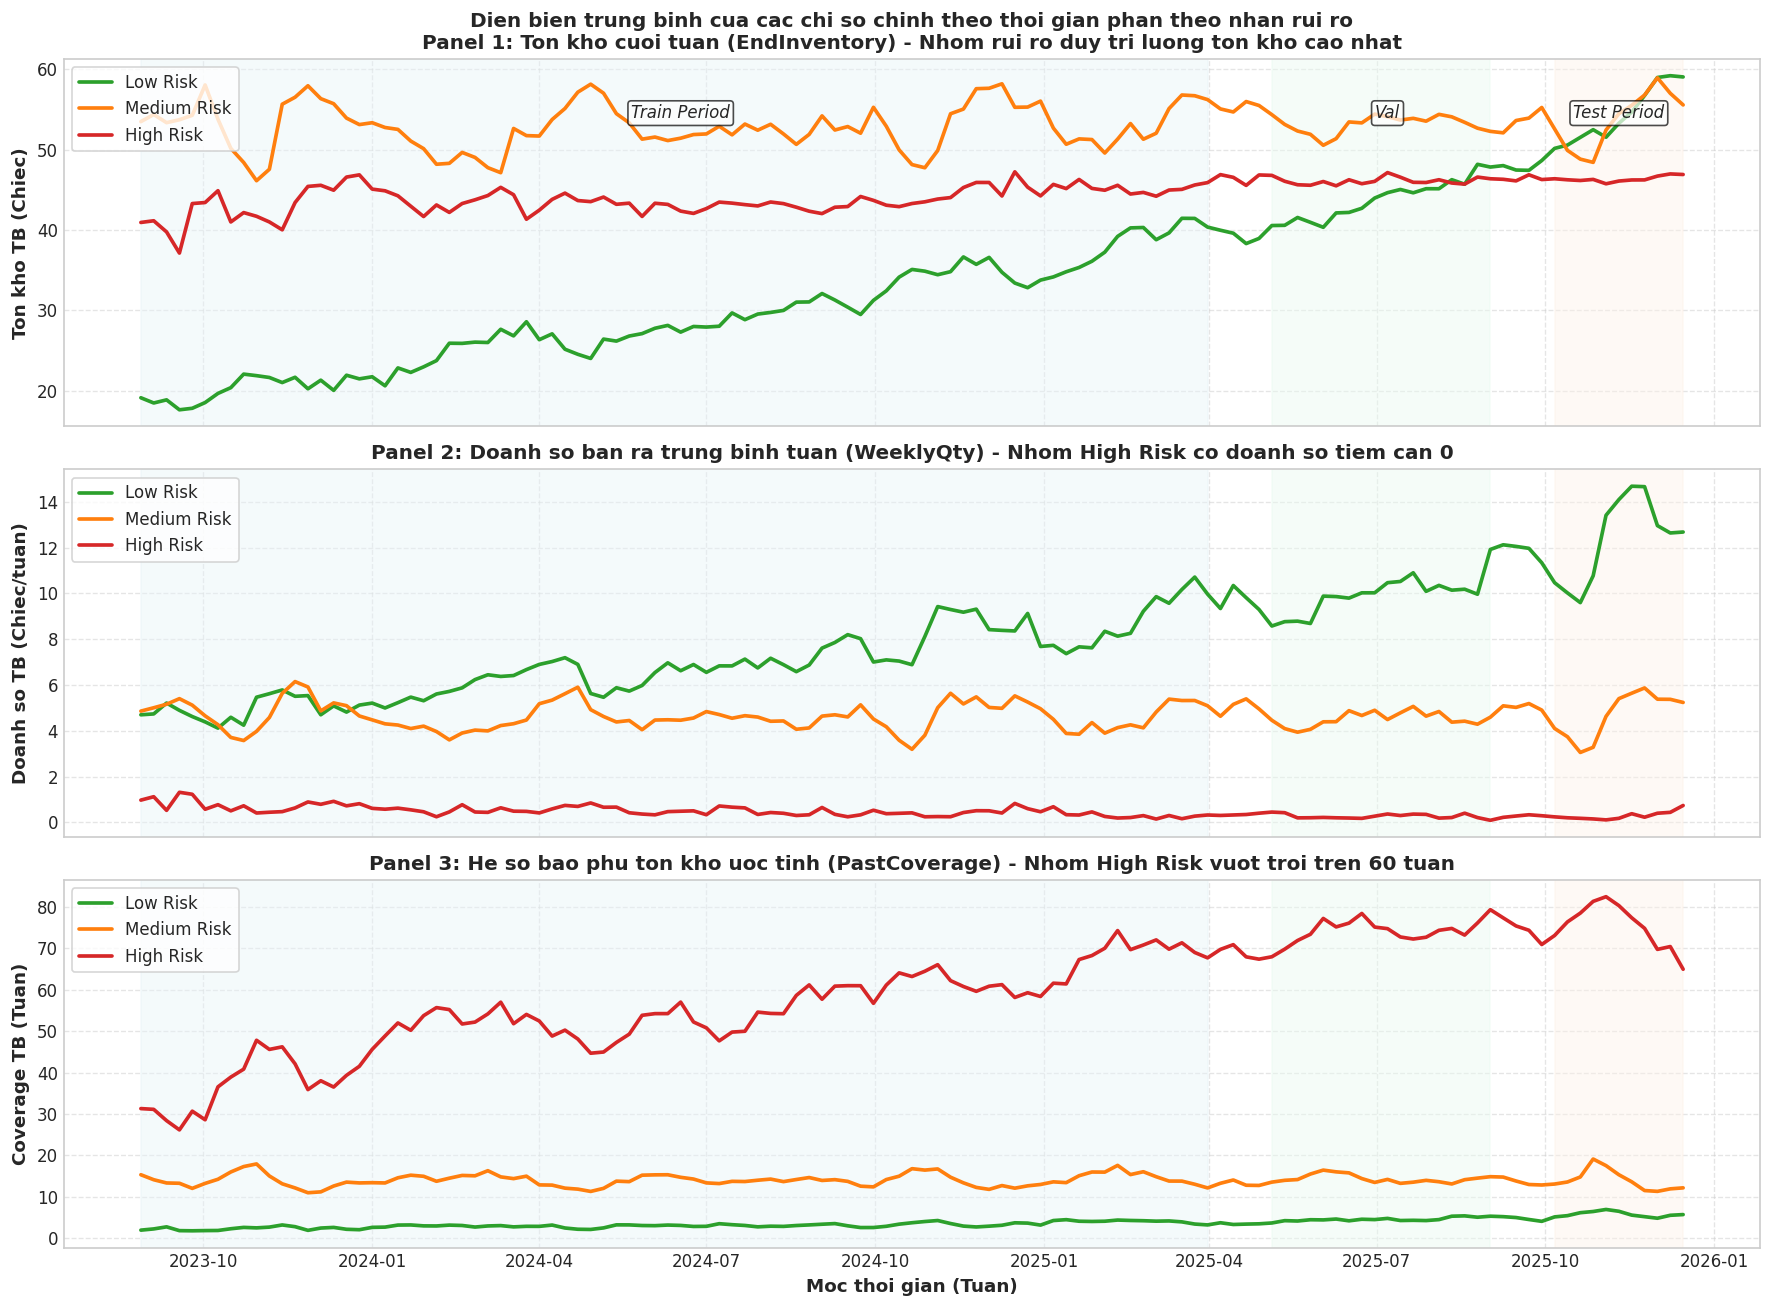


--- GIAI THICH NGUYEN LY PHAN LOP CUA MO HINH (BUSINESS INSIGHTS) ---
1. Su phan ky (Divergence) giua Ton kho va Doanh so:
   - Nhom High Risk (Mau do): Luong ton kho trung binh luon duy tri o muc rat cao (~45 - 55 chiec), nhung doanh so ban WeeklyQty lai roi tham hai ve sat 0 (chi dat ~0.38 chiec/tuan).
   - Nhom Low Risk (Mau xanh): Doanh so ban luon cao vuot troi (~7.5 chiec/tuan), ton kho duoc giai phong nhanh chong giup Coverage chi o muc 3.4 tuan.
2. Ly do mo hinh dat hieu nang cao (PR-AUC ~ 0.98):
   - Giua cac nhan co ranh gioi phan tach ro rang qua PastCoverage va su doi lap giua EndInventory va SalesTrend_4w.
   - Nho do, LightGBM de dang nhan dien cac SKU bi 'dong bang' tieu thu nhung van u dong ton kho lon.


In [13]:
# 3. Bieu do xu huong trung binh cua cac chi so chinh theo thoi gian nhom theo nhan rui ro
# Giai thich sinh dong co che phan tach cua mo hinh qua su phan ky (divergence) giua Ton kho va Doanh so

# Gan nhan Target tren toan bo valid_df bang nguong P60, P85 tu Train de khao sat xuyen suot chuoi thoi gian
valid_df['Target'] = np.where(
    (valid_df['Coverage'] >= p85) & (valid_df['SalesTrend_4w'] <= 0), 2,
    np.where(valid_df['Coverage'] >= p60, 1, 0)
)

weekly_risk_stats = valid_df.groupby(['Week', 'Target']).agg(
    Avg_EndInventory=('EndInventory', 'mean'),
    Avg_WeeklyQty=('WeeklyQty', 'mean'),
    Avg_PastCoverage=('PastCoverage', 'mean'),
    Avg_SalesTrend=('SalesTrend_4w', 'mean')
).reset_index()

risk_colors = {0: '#2ca02c', 1: '#ff7f0e', 2: '#d62728'}
risk_names = {0: 'Low Risk', 1: 'Medium Risk', 2: 'High Risk'}

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)

# 1. Panel Ton kho trung binh (EndInventory)
for r in [0, 1, 2]:
    subset = weekly_risk_stats[weekly_risk_stats['Target'] == r]
    axes[0].plot(subset['Week'], subset['Avg_EndInventory'], label=risk_names[r],
                 color=risk_colors[r], lw=2.2)
axes[0].set_ylabel('Ton kho TB (Chiec)', fontsize=11, fontweight='bold')
axes[0].set_title('Dien bien trung binh cua cac chi so chinh theo thoi gian phan theo nhan rui ro\nPanel 1: Ton kho cuoi tuan (EndInventory) - Nhom rui ro duy tri luong ton kho cao nhat', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper left', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Panel Doanh so ban trung binh (WeeklyQty)
for r in [0, 1, 2]:
    subset = weekly_risk_stats[weekly_risk_stats['Target'] == r]
    axes[1].plot(subset['Week'], subset['Avg_WeeklyQty'], label=risk_names[r],
                 color=risk_colors[r], lw=2.2)
axes[1].set_ylabel('Doanh so TB (Chiec/tuan)', fontsize=11, fontweight='bold')
axes[1].set_title('Panel 2: Doanh so ban ra trung binh tuan (WeeklyQty) - Nhom High Risk co doanh so tiem can 0', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper left', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Panel He so bao phu ton kho (PastCoverage)
for r in [0, 1, 2]:
    subset = weekly_risk_stats[weekly_risk_stats['Target'] == r]
    axes[2].plot(subset['Week'], subset['Avg_PastCoverage'], label=risk_names[r],
                 color=risk_colors[r], lw=2.2)
axes[2].set_ylabel('Coverage TB (Tuan)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Moc thoi gian (Tuan)', fontsize=11, fontweight='bold')
axes[2].set_title('Panel 3: He so bao phu ton kho uoc tinh (PastCoverage) - Nhom High Risk vuot troi tren 60 tuan', fontsize=12, fontweight='bold')
axes[2].legend(loc='upper left', frameon=True)
axes[2].grid(True, linestyle='--', alpha=0.5)

# Danh dau cac vung phan chia thoi gian (Train, Gap 1, Val, Gap 2, Test)
split_dates = [
    (train_weeks[0], train_weeks[-1], 'Train Set', '#e8f4f8'),
    (val_weeks[0], val_weeks[-1], 'Val Set', '#eafaf1'),
    (test_weeks[0], test_weeks[-1], 'Test Set', '#fdf2e9')
]
for start, end, label, color in split_dates:
    for ax in axes:
        ax.axvspan(start, end, color=color, alpha=0.45)

axes[0].text(train_weeks[len(train_weeks)//2], axes[0].get_ylim()[1]*0.88, 'Train Period', ha='center', fontsize=10, fontstyle='italic', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))
axes[0].text(val_weeks[len(val_weeks)//2], axes[0].get_ylim()[1]*0.88, 'Val', ha='center', fontsize=10, fontstyle='italic', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))
axes[0].text(test_weeks[len(test_weeks)//2], axes[0].get_ylim()[1]*0.88, 'Test Period', ha='center', fontsize=10, fontstyle='italic', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))

plt.tight_layout()
plt.show()

print("\n--- GIAI THICH NGUYEN LY PHAN LOP CUA MO HINH (BUSINESS INSIGHTS) ---")
print("1. Su phan ky (Divergence) giua Ton kho va Doanh so:")
print("   - Nhom High Risk (Mau do): Luong ton kho trung binh luon duy tri o muc rat cao (~45 - 55 chiec), nhung doanh so ban WeeklyQty lai roi tham hai ve sat 0 (chi dat ~0.38 chiec/tuan).")
print("   - Nhom Low Risk (Mau xanh): Doanh so ban luon cao vuot troi (~7.5 chiec/tuan), ton kho duoc giai phong nhanh chong giup Coverage chi o muc 3.4 tuan.")
print("2. Ly do mo hinh dat hieu nang cao (PR-AUC ~ 0.98):")
print("   - Giua cac nhan co ranh gioi phan tach ro rang qua PastCoverage va su doi lap giua EndInventory va SalesTrend_4w.")
print("   - Nho do, LightGBM de dang nhan dien cac SKU bi 'dong bang' tieu thu nhung van u dong ton kho lon.")

In [14]:
# 2.4. Huan luyen cac mo hinh Baseline va PP-A (LightGBM)
features = [
    'WeeklyQty', 'WeeklyRevenue', 'AvgPrice', 'PromoCount', 'NetQtyChange', 'EndInventory',
    'Sales_Lag_1', 'Sales_Lag_2', 'Sales_Lag_4', 'Sales_Lag_8',
    'Sales_RollingMean_4w', 'Sales_RollingStd_4w', 'Sales_RollingMean_8w',
    'SalesTrend_4w', 'PastCoverage', 'Month', 'WeekOfYear'
]

X_train, y_train = train_set[features].fillna(0), train_set['Target']
X_test, y_test = test_set[features].fillna(0), test_set['Target']

# Model 1: Heuristic Rule-based Threshold (dung PastCoverage)
test_set['Pred_Rule'] = np.where(
    (test_set['PastCoverage'] >= p85) & (test_set['SalesTrend_4w'] <= 0), 2,
    np.where(test_set['PastCoverage'] >= p60, 1, 0)
)
y_pred_rule = test_set['Pred_Rule']

# Model 2: Dummy Classifier (Stratified)
dummy = DummyClassifier(strategy='stratified', random_state=42)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

# Model 3: Logistic Regression (Multinomial, class_weight='balanced')
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(max_iter=500, class_weight='balanced', random_state=42)
t_lr_start = time.time()
lr.fit(X_train_scaled, y_train)
t_lr_train = time.time() - t_lr_start
y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 2]

# Model 4: LightGBM Classifier (PP-A, class_weight='balanced')
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
t_lgb_start = time.time()
lgb_model.fit(X_train, y_train)
t_lgb_train = time.time() - t_lgb_start
y_pred_lgb = lgb_model.predict(X_test)
y_prob_lgb = lgb_model.predict_proba(X_test)[:, 2]

print(f"Huan luyen hoan tat! Thoi gian train LR: {t_lr_train:.2f}s | LightGBM: {t_lgb_train:.2f}s")

Huan luyen hoan tat! Thoi gian train LR: 0.64s | LightGBM: 0.93s


In [15]:
# 2.5. Bang so sanh hieu nang cac mo hinh
model_dict = {
    'Dummy Classifier (Stratified)': (y_pred_dummy, None),
    'Rule-based Threshold Baseline': (y_pred_rule, None),
    'Logistic Regression (Balanced)': (y_pred_lr, y_prob_lr),
    'LightGBM Classifier (PP-A)':     (y_pred_lgb, y_prob_lgb)
}

results = []
for name, (pred, prob) in model_dict.items():
    acc = accuracy_score(y_test, pred)
    rec_high = recall_score(y_test, pred, labels=[2], average=None)[0]
    prec_high = precision_score(y_test, pred, labels=[2], average=None)[0]
    macro_f1 = f1_score(y_test, pred, average='macro')
    
    if prob is not None:
        p_c, r_c, _ = precision_recall_curve((y_test == 2).astype(int), prob)
        pr_auc = auc(r_c, p_c)
    else:
        pr_auc = np.nan
        
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Recall (High Risk)': rec_high,
        'Precision (High Risk)': prec_high,
        'Macro-F1': macro_f1,
        'PR-AUC (High Risk)': pr_auc
    })

eval_df = pd.DataFrame(results)
print("=== BANG TONG HOP KET QUA KIEM CHUNG TREN TAP TEST ===")
print(eval_df.to_string(index=False))

=== BANG TONG HOP KET QUA KIEM CHUNG TREN TAP TEST ===
                         Model  Accuracy  Recall (High Risk)  Precision (High Risk)  Macro-F1  PR-AUC (High Risk)
 Dummy Classifier (Stratified)    0.3512              0.1199                 0.2771    0.3078                 NaN
 Rule-based Threshold Baseline    0.8223              0.8901                 0.9271    0.8298                 NaN
Logistic Regression (Balanced)    0.7856              0.9170                 0.8064    0.7910              0.9568
    LightGBM Classifier (PP-A)    0.8428              0.9393                 0.8858    0.8486              0.9802


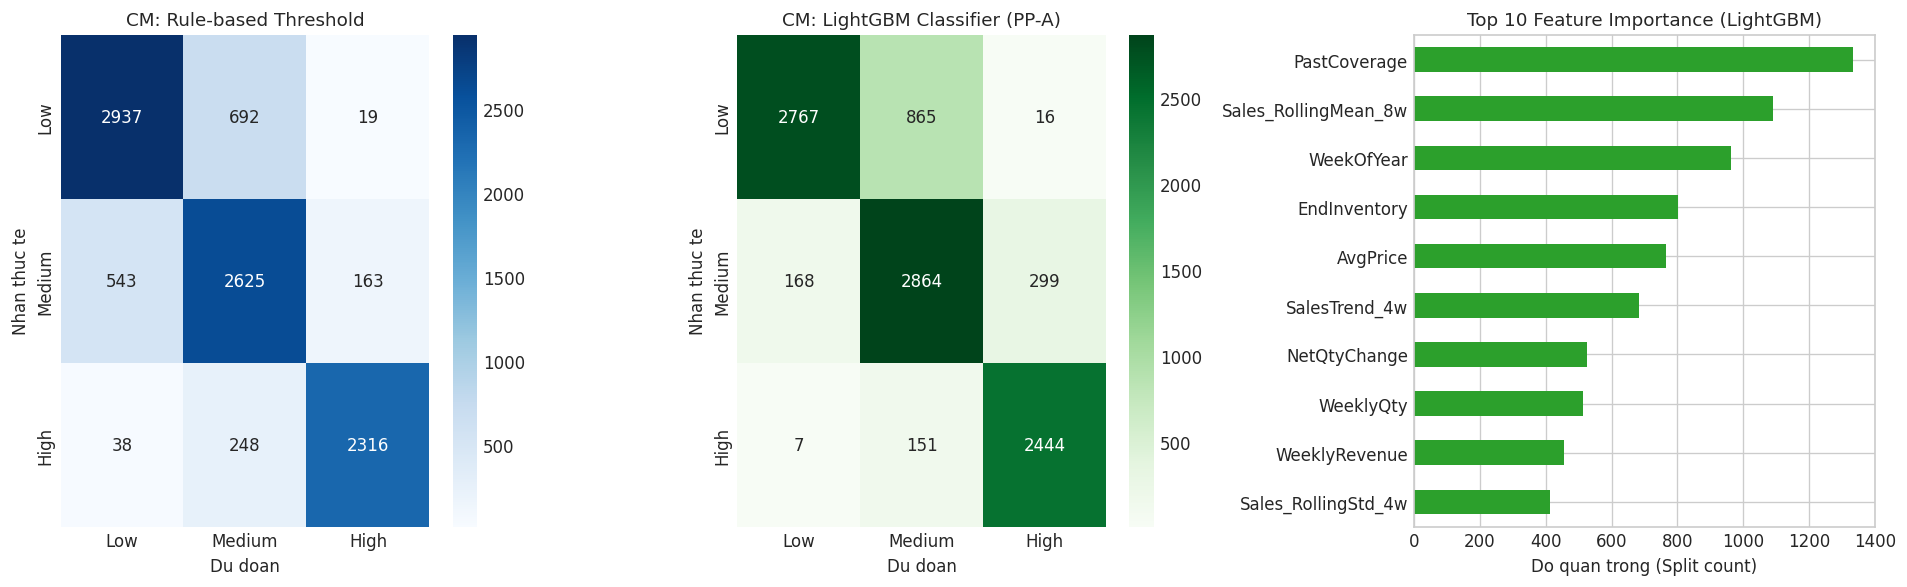

In [16]:
# Truc quan hoa Confusion Matrix va Feature Importance
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Confusion Matrix: Rule-based
cm_rule = confusion_matrix(y_test, y_pred_rule, labels=[0, 1, 2])
sns.heatmap(cm_rule, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
axes[0].set_title('CM: Rule-based Threshold')
axes[0].set_ylabel('Nhan thuc te')
axes[0].set_xlabel('Du doan')

# 2. Confusion Matrix: LightGBM
cm_lgb = confusion_matrix(y_test, y_pred_lgb, labels=[0, 1, 2])
sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
axes[1].set_title('CM: LightGBM Classifier (PP-A)')
axes[1].set_ylabel('Nhan thuc te')
axes[1].set_xlabel('Du doan')

# 3. Feature Importance LightGBM
imp = pd.Series(lgb_model.feature_importances_, index=features).sort_values(ascending=True)
imp.tail(10).plot(kind='barh', color='#2ca02c', ax=axes[2])
axes[2].set_title('Top 10 Feature Importance (LightGBM)')
axes[2].set_xlabel('Do quan trong (Split count)')

plt.tight_layout()
plt.show()

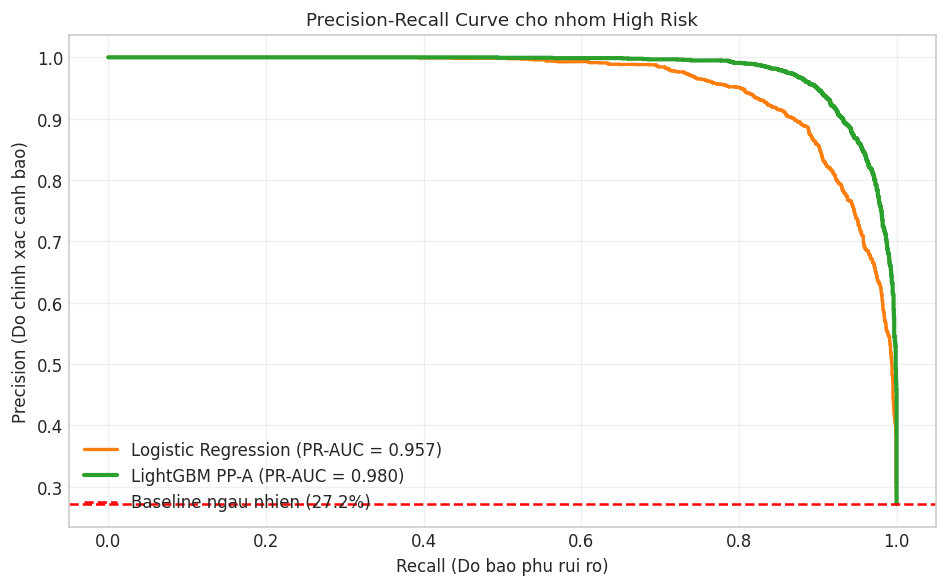

In [17]:
# Truc quan hoa Precision-Recall Curve cho lop High Risk
fig, ax = plt.subplots(figsize=(8, 5))

p_lr, r_lr, _ = precision_recall_curve((y_test == 2).astype(int), y_prob_lr)
ax.plot(r_lr, p_lr, label=f'Logistic Regression (PR-AUC = {auc(r_lr, p_lr):.3f})', color='#ff7f0e', lw=2)

p_lgb, r_lgb, _ = precision_recall_curve((y_test == 2).astype(int), y_prob_lgb)
ax.plot(r_lgb, p_lgb, label=f'LightGBM PP-A (PR-AUC = {auc(r_lgb, p_lgb):.3f})', color='#2ca02c', lw=2.5)

ax.axhline((y_test == 2).mean(), color='red', linestyle='--', label=f'Baseline ngau nhien ({100*(y_test==2).mean():.1f}%)')
ax.set_title('Precision-Recall Curve cho nhom High Risk')
ax.set_xlabel('Recall (Do bao phu rui ro)')
ax.set_ylabel('Precision (Do chinh xac canh bao)')
ax.legend(loc='lower left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()